# 16장 실습. 모델 레지스트리와 회귀 테스트

14장에서 체크포인트가 생겼다. 운영에 올리려면 네 가지가 더 필요하다. 어떤 데이터와 설정으로 만든 무엇인지 기록하고(레지스트리), 정해진 버전을 받아 쓰고(revision 고정), 새 버전이 옛 버전보다 나빠지지 않았는지 막고(회귀 게이트), 올린 뒤에도 지켜본다(모니터링).

| 절 | 내용 |
|---|---|
| 16.1 | 레지스트리 — 체크포인트마다 출처·지표·해시를 한 줄로, 후보는 해시로 지정 |
| 16.2 | Hugging Face Hub 업로드와 revision 고정 (선택) |
| 16.3 | 회귀 게이트 — 짝지은 비교 + 골든 케이스, 같은 후보로 |
| 16.4 | laya-serve 에 올려 이름으로 부르기 |
| 16.5 | 모니터링 — 확신 분포의 이동(PSI)과 기권률, 경보 기준을 무변화 데이터로 정하기 |

GPU 도 Jev 키도 필요 없다. 14장의 `models/` 와 `results/eval_v1/laya-ft-*` 를 쓴다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

import laya

def checkpoint_engine(path, **load_kwargs):
    agent = laya.load(str(path), **load_kwargs)
    def post(state, questions):
        t0 = time.perf_counter()
        r = agent.predict(state, questions)
        return r | {"model": "laya:" + Path(path).name, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
    post.agent = agent
    return post

import hashlib, subprocess, sys
MODELS, RESULTS = Path("models"), Path("results/eval_v1")
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
by_task = lambda rs, t: [r for r in rs if r["task"] == t]

CANDIDATE = "rlcd-human"                   # 운영에 올릴 후보. 16.1 에서 이 이름의 가중치 해시를 고정하고, 이후 모든 절이 그 해시로 확인한다
BASELINE = "laya-routed"                   # 지금 쓰는 엔진의 평가 기록 (12장의 Laya 기본)

## 16.1 모델 레지스트리

체크포인트마다 한 줄을 남긴다. 무엇에서 출발했고, 어떤 교사 데이터로(해시), 어떤 설정으로 학습했고, 평가셋(해시)에서 어떤 숫자가 나왔는지, 가중치 파일의 해시는 무엇인지다. 해시가 있어야 「지난주 그 모델」을 정확히 가리킬 수 있다.

2판에서는 후보를 「이름순 첫 체크포인트」로 골라, 게이트와 골든 케이스가 서로 다른 체크포인트를 봤다. 이번에는 후보를 이름으로 정하고 그 가중치 해시를 고정한다. 뒤의 절은 모두 이 해시가 맞는지 확인하고 시작한다.

In [2]:
train_card = json.loads((DATA / "train" / "card.json").read_text())
eval_sha = json.loads((DATA / "eval_v1.card.json").read_text())["sha256"]

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    return float(np.max(k[np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)], initial=0) / len(conf))

def entry(path):
    cfg = json.loads((path / "rl_agent_config.json").read_text())
    recs = read_jsonl(RESULTS / f"laya-ft-{path.name}.records.jsonl")
    return {"name": path.name, "weights_sha256": sha(path / "model.safetensors"), "temperature": [round(t, 3) for t in cfg["temperature"]],
            "train_data": cfg.get("training", {}).get("laya_train", {}).get("data"), "teachers_card": train_card["teachers"], "eval_sha256": eval_sha,
            "accuracy": arrays(recs)[1].mean(), "ece": ece(*arrays(recs)), "coverage@5%": coverage_at_risk(*arrays(recs)),
            "registered_at": time.strftime("%Y-%m-%d %H:%M")}

checkpoints = sorted(p.parent for p in MODELS.glob("*/rl_agent_config.json"))
registry = [entry(p) for p in checkpoints]
write_jsonl(MODELS / "registry.jsonl", registry)
PINNED = next(r["weights_sha256"] for r in registry if r["name"] == CANDIDATE)
print("후보", CANDIDATE, "| 가중치 해시", PINNED[:16])
pd.DataFrame(registry)[["name", "weights_sha256", "accuracy", "ece", "coverage@5%", "temperature"]].assign(weights_sha256=lambda d: d["weights_sha256"].str[:16])

후보 rlcd-human | 가중치 해시 5e83c9fcead1b58f


,name,weights_sha256,accuracy,ece,coverage@5%,temperature
0,ddp-human,9d5217efd3de7b85,0.730,0.050,0.181,"[1.463, 1.209, 2.627]"
1,rlcd-human,5e83c9fcead1b58f,0.715,0.027,0.165,"[1.444, 1.215, 2.633]"
2,rlcd-llm,a01fcf4b7824fcb4,0.665,0.059,0.083,"[1.275, 1.12, 1.251]"
3,rlcd-mix,2b5eefde3dfd6a10,0.729,0.049,0.367,"[1.133, 1.215, 1.359]"
4,softce-human,36572becc90072b8,0.728,0.044,0.250,"[1.51, 1.438, 2.783]"


평가 기록이 없는 체크포인트는 `entry()` 에서 파일을 찾지 못해 멈춘다. 레지스트리에는 잰 체크포인트만 올린다는 규칙을 코드가 지키는 셈이다. 14장에서 DDP 를 돌렸다면 `laya-ft-ddp-human` 기록도 함께 남겼으므로 그대로 올라간다.

## 16.2 Hub 업로드와 revision 고정

`laya.load(저장소, revision=커밋)` 은 정해진 커밋의 가중치만 받는다. 저장소의 최신 파일이 바뀌어도 운영 모델은 바뀌지 않는다. 올린 커밋 해시를 레지스트리에 함께 적는다.

`.env` 에 `HF_TOKEN` 과 `HF_REPO`(예: `my-org/laya-ko-ticket`)를 넣은 뒤 아래를 셀에 붙여 실행한다. 비공개 저장소를 만들고, 후보를 올리고, 올린 커밋으로 다시 받는다.

```python
from huggingface_hub import HfApi
repo = os.environ["HF_REPO"]
HfApi().create_repo(repo, private=True, exist_ok=True)
commit = HfApi().upload_folder(repo_id=repo, folder_path=str(MODELS / CANDIDATE), commit_message=f"{CANDIDATE} {PINNED[:12]}")
pinned = laya.load(repo, revision=commit.oid)          # 이 커밋의 가중치만 받는다
```

## 16.3 회귀 게이트와 골든 케이스

후보를 지금 쓰는 것(baseline)과 같은 평가셋에서 짝지어 비교한다. 규칙은 미리 정해 두고 숫자가 나온 뒤에 고치지 않는다.

| 규칙 | 기준 |
|---|---|
| 정확도 | 과제마다 차이의 95% 구간 하한이 −0.03 보다 크다 (확실히 나빠지지 않았다) |
| 보정 | 과제마다 ECE 가 baseline + 0.03 이하 |
| 처리율 | 과제마다 처리율@5% 가 baseline − 0.05 이상 |
| 골든 케이스 | 반드시 맞혀야 하는 사례를 모두 맞힌다 |

게이트를 돌리기 전에 디스크의 후보 가중치가 레지스트리에 고정한 해시와 같은지 확인한다.

In [3]:
assert sha(MODELS / CANDIDATE / "model.safetensors") == PINNED, "후보 가중치가 레지스트리의 해시와 다르다"
base, cand = read_jsonl(RESULTS / f"{BASELINE}.records.jsonl"), read_jsonl(RESULTS / f"laya-ft-{CANDIDATE}.records.jsonl")

def gate_row(t, d_acc=-0.03, d_ece=0.03, d_cov=-0.05, n_boot=2000):
    b_, c = by_task(base, t), {r["id"]: r for r in by_task(cand, t)}
    ca, cb = np.array([r["correct"] for r in b_], float), np.array([c[r["id"]]["correct"] for r in b_], float)
    idx = np.random.default_rng(0).integers(0, len(ca), (n_boot, len(ca)))
    low = np.percentile(cb[idx].mean(1) - ca[idx].mean(1), 2.5)
    (fb, yb), (fc, yc) = arrays(b_), arrays(list(c.values()))
    return {"과제": t, "정확도 차이": cb.mean() - ca.mean(), "구간 하한": low, "정확도 통과": low > d_acc,
            "ECE": ece(fc, yc), "ECE 통과": ece(fc, yc) <= ece(fb, yb) + d_ece,
            "처리율@5%": coverage_at_risk(fc, yc), "처리율 통과": coverage_at_risk(fc, yc) >= coverage_at_risk(fb, yb) + d_cov}

gate = pd.DataFrame([gate_row(t) for t in TASKS]).set_index("과제")
print(f"baseline={BASELINE}  candidate={CANDIDATE} ({PINNED[:12]})")
gate

baseline=laya-routed  candidate=rlcd-human (5e83c9fcead1)


,정확도 차이,구간 하한,정확도 통과,ECE,ECE 통과,처리율@5%,처리율 통과
과제,,,,,,,
topic,0.405,0.325,True,0.063,True,0.045,True
entails,-0.010,-0.045,False,0.069,True,0.745,True
positive,0.110,0.035,True,0.078,True,0.335,True
similarity,0.330,0.245,True,0.072,True,0.005,True


In [4]:
# 골든 케이스: 틀리면 다른 숫자가 좋아도 배포하지 않는 사례. 게이트와 같은 후보 체크포인트로 잰다
post = checkpoint_engine(MODELS / CANDIDATE)
EQ = {i["task"]: i["questions"] for i in read_jsonl(DATA / "eval_v1.jsonl")}
TICKET_STATE = {"channel": "앱 문의", "message": "결제가 두 번 됐어요. 어제 저녁에 한 번만 결제했는데 카드 문자가 두 번 왔습니다. 오늘 안에 처리 안 되면 해지할게요."}
TICKET_Q = {"department": {"type": "choice", "instructions": "이 문의를 처리할 팀", "criteria": {"billing": "결제, 환불, 청구 오류",
            "technical": "앱 오류, 로그인, 연동 문제", "account": "가입, 해지, 요금제 변경", "general": "그 밖의 문의"}},
            "churn_risk": {"type": "noul", "instructions": "고객이 해지를 언급하거나 해지할 뜻을 보인다"}}
GOLDEN = [("결제 중복 → billing", TICKET_STATE, TICKET_Q, lambda a: a["department"]["choice"] == "billing"),
          ("해지 예고 → churn ≥ 0.5", TICKET_STATE, TICKET_Q, lambda a: a["churn_risk"]["noul"] >= 0.5),
          ("명백한 긍정 리뷰", "인생 영화입니다. 두 번 봤고 또 볼 거예요.", EQ["positive"], lambda a: a["positive"]["noul"] >= 0.5),
          ("명백한 부정 리뷰", "돈 아깝다. 중간에 나왔음.", EQ["positive"], lambda a: a["positive"]["noul"] < 0.5),
          ("스포츠 기사", "손흥민 시즌 10호골…토트넘 2-0 승리", EQ["topic"], lambda a: a["topic"]["choice"] == "스포츠")]
golden = pd.DataFrame([{"사례": name, "통과": bool(check(post(s, q)["answers"]))} for name, s, q, check in GOLDEN])
verdict = bool(gate[["정확도 통과", "ECE 통과", "처리율 통과"]].all().all() and golden["통과"].all())
display(golden)
print("배포 판정:", ["막음", "통과"][verdict])

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,사례,통과
0,결제 중복 → billing,True
1,해지 예고 → churn ≥ 0.5,True
2,명백한 긍정 리뷰,True
3,명백한 부정 리뷰,True
4,스포츠 기사,True


배포 판정: 막음


In [5]:
# 같은 회귀 세트를 laya-evals 형식(expected)으로 내보내고, 가중치 없이 형식만 검사한다
EXPECTED = {"noul": bool, "choice": str, "score": int}
reg = [{"id": i["id"], "state": i["state"], "questions": i["questions"], "tags": [i["task"]],
        "expected": {i["task"]: EXPECTED[i["questions"][i["task"]]["type"]](i["gold"])}} for i in read_jsonl(DATA / "eval_v1.jsonl")]
write_jsonl(MODELS / "regression_v1.jsonl", reg)
print(subprocess.run([sys.executable, "-m", "laya.evals_cli", "validate", str(MODELS / "regression_v1.jsonl")], capture_output=True, text=True).stdout[-600:])

800 examples, 4 question id(s): entails, positive, similarity, topic



## 16.4 laya-serve 체크포인트 등록

`LAYA_EXTRA_MODELS` 에 이름과 경로를 주면 laya-serve 가 체크포인트를 그 이름으로 연다. 요청의 `model` 필드에 그 이름을 적으면 라우팅 없이 그 체크포인트가 답한다. Jev 모델 이름을 주면 10장의 Router 가 고른 체크포인트가 답한다.

In [6]:
PORT = 8766
URL = f"http://127.0.0.1:{PORT}"
env = os.environ | {"LAYA_HOST": "127.0.0.1", "LAYA_PORT": str(PORT), "LAYA_EXTRA_MODELS": json.dumps({CANDIDATE: str((MODELS / CANDIDATE).resolve())}), "LAYA_API_KEY": ""}
log = open(OUT / "laya-serve-16.log", "w")
server = subprocess.Popen([sys.executable, "-m", "laya.serve"], env=env, stdout=log, stderr=subprocess.STDOUT)
http = requests.Session()
http.mount(URL, HTTPAdapter(max_retries=Retry(total=10, connect=10, backoff_factor=0.5, status_forcelist=[502, 503, 504])))
http.get(f"{URL}/health", timeout=5)

for model in [CANDIDATE, "jev-latest"]:
    r = http.post(f"{URL}/v1/systemone", json={"model": model, "state": TICKET_STATE, "questions": TICKET_Q}, timeout=60).json()
    print(f"model={model:<14} → routing {r['routing']['model']:<14} department={r['answers']['department']['choice']}  p={r['answers']['department']['answer_confidence']:.2f}")
server.terminate(); server.wait(timeout=30); log.close()

model=rlcd-human     → routing rlcd-human     department=billing  p=0.67
model=jev-latest     → routing multilingual   department=billing  p=0.96


## 16.5 PSI 와 기권률 모니터링

운영에서는 정답이 늦게 온다. 그래서 라벨 없이 볼 수 있는 신호부터 본다. 확신 분포가 기준과 달라졌는지(PSI, Population Stability Index), 임계값 아래로 떨어져 사람에게 가는 비율(기권률)이다.

영화 리뷰를 positive 질문으로 판단하는 서비스를 7일 돌린다고 하자. 하루 120건이다. 1~4일은 평가셋에 없는 NSMC 리뷰만 들어오고, 5~7일에는 절반이 뉴스 제목이다.

2판에서는 PSI 의 관행 기준(0.1 주의, 0.25 조사)을 그대로 써서 입력이 바뀌지 않은 날에도 경보가 났다. 표본이 작으면 분포가 같아도 PSI 가 우연히 커진다. 이번에는 경보 기준을 이 서비스의 무변화 데이터로 정한다. 리뷰만 120건씩 뽑아 기준과 비교하기를 500번 하고, 그 PSI 의 95분위를 경보 기준으로 쓴다.

In [7]:
import csv
from collections import Counter

RAW = DATA / "raw"
EVAL_Q = {i["task"]: i["questions"] for i in read_jsonl(DATA / "eval_v1.jsonl")}      # 평가셋과 같은 질문을 쓴다
TOPICS = list(EVAL_Q["topic"]["topic"]["criteria"])
load_json = lambda name: json.loads((RAW / name).read_text(encoding="utf-8"))

def load_nsmc(name):
    rows = list(csv.DictReader((RAW / name).open(encoding="utf-8"), delimiter="\t", quoting=csv.QUOTE_NONE))
    return [r for r in rows if r["document"] and r["document"].strip()]

def item_topic(r):
    votes = Counter(r["annotations"]["annotations"]["first-scope"])
    return {"id": r["guid"], "task": "topic", "state": r["title"], "gold": r["label"], "gold_dist": {k: votes.get(k, 0) / sum(votes.values()) for k in TOPICS}}

def item_entails(r):
    votes = [r[k] for k in ("author", "label2", "label3", "label4", "label5")]
    return {"id": r["guid"], "task": "entails", "state": {"premise": r["premise"], "hypothesis": r["hypothesis"]},
            "gold": r["gold_label"] == "entailment", "gold_dist": {"true": votes.count("entailment") / len(votes)}}

def item_positive(r):
    return {"id": f"nsmc_{r['id']}", "task": "positive", "state": r["document"].strip(), "gold": r["label"] == "1", "gold_dist": None}

def item_similarity(r):
    c = Counter(int(round(a)) for a in r["annotations"]["annotations"])
    return {"id": r["guid"], "task": "similarity", "state": {"sentence1": r["sentence1"], "sentence2": r["sentence2"]},
            "gold": int(round(r["labels"]["label"])), "gold_value": r["labels"]["label"], "gold_dist": {str(k): c.get(k, 0) / sum(c.values()) for k in range(6)}}

TRAIN_SOURCES = {"topic": ("ynat-v1.1_train.json", load_json, item_topic), "entails": ("klue-nli-v1.1_train.json", load_json, item_entails),
                 "positive": ("ratings_train.txt", load_nsmc, item_positive), "similarity": ("klue-sts-v1.1_train.json", load_json, item_similarity)}
load_train = lambda task: [TRAIN_SOURCES[task][2](r) for r in TRAIN_SOURCES[task][1](TRAIN_SOURCES[task][0])]

rng = np.random.default_rng(0)
eval_ids = {i["id"] for i in read_jsonl(DATA / "eval_v1.jsonl")}
reviews = [i["state"] for i in random.Random(0).sample(load_train("positive"), 5000) if i["id"] not in eval_ids]
titles = [i["state"] for i in random.Random(0).sample(load_train("topic"), 1000)]
days = {d: list(rng.choice(reviews, 120)) for d in range(1, 5)} | {d: list(rng.choice(reviews, 60)) + list(rng.choice(titles, 60)) for d in range(5, 8)}

Q = EQ["positive"]
conf_of = lambda texts: np.array([max(p, 1 - p) for p in [post(s, Q)["answers"]["positive"]["noul"] for s in texts]])
ref = conf_of([i["state"] for i in read_jsonl(DATA / "eval_v1.jsonl") if i["task"] == "positive"])
pool = conf_of(reviews[:1200])                         # 무변화 데이터: 리뷰만
conf = {d: conf_of(texts) for d, texts in days.items()}

def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    a = np.histogram(np.clip(ref, edges[0], edges[-1]), edges)[0] / len(ref) + 1e-4
    b_ = np.histogram(np.clip(cur, edges[0], edges[-1]), edges)[0] / len(cur) + 1e-4
    return float(((b_ - a) * np.log(b_ / a)).sum())

null = np.array([psi(ref, rng.choice(pool, 120)) for _ in range(500)])
ALARM = np.quantile(null, 0.95)
print(f"무변화일 때 PSI 중앙값 {np.median(null):.3f}, 95분위 {ALARM:.3f} | 이론값 (k−1)(1/n₁+1/n₂) = {9 * (1 / len(ref) + 1 / 120):.3f}")

THRESHOLD = 0.7
monitor = pd.DataFrame({d: {"평균 확신": c.mean(), "기권률 (확신 < 0.7)": (c < THRESHOLD).mean(), "PSI": psi(ref, c)} for d, c in conf.items()}).T.rename_axis("일")
monitor["관행 기준"] = pd.cut(monitor["PSI"], [-1, 0.1, 0.25, 99], labels=["안정", "주의", "조사"])
monitor["이 서비스 기준"] = np.where(monitor["PSI"] > ALARM, "경보", "정상")
monitor

무변화일 때 PSI 중앙값 0.095, 95분위 0.192 | 이론값 (k−1)(1/n₁+1/n₂) = 0.120


,평균 확신,기권률 (확신 < 0.7),PSI,관행 기준,이 서비스 기준
일,,,,,
1,0.860,0.092,0.116,주의,정상
2,0.855,0.142,0.148,주의,정상
3,0.870,0.100,0.190,주의,정상
4,0.858,0.125,0.084,안정,정상
5,0.825,0.133,0.185,주의,정상
6,0.843,0.125,0.087,안정,정상
7,0.846,0.092,0.206,주의,경보


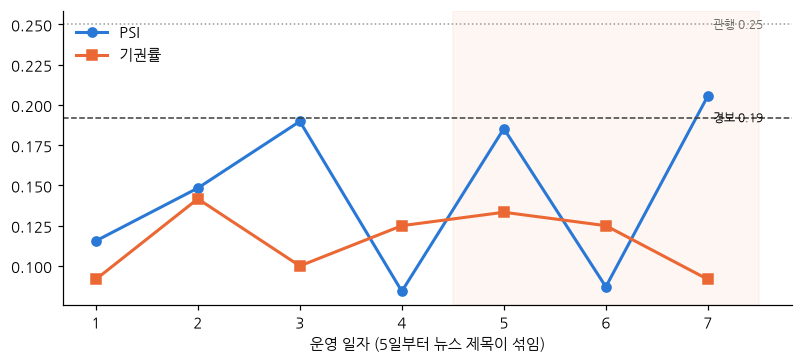

In [8]:
fig, ax = plt.subplots(figsize=(7.4, 3.4), dpi=110)
ax.plot(monitor.index, monitor["PSI"], marker="o", color="#2a78d6", lw=2, label="PSI")
ax.plot(monitor.index, monitor["기권률 (확신 < 0.7)"], marker="s", color="#eb6834", lw=2, label="기권률")
ax.axhline(ALARM, ls="--", lw=1, color="#3d3d3a"); ax.text(7.05, ALARM, f"경보 {ALARM:.2f}", fontsize=8, va="center")
ax.axhline(0.25, ls=":", lw=1, color="#9a9a96"); ax.text(7.05, 0.25, "관행 0.25", fontsize=8, color="#6b6b66", va="center")
ax.axvspan(4.5, 7.5, color="#eb6834", alpha=0.06)
ax.set_xlabel("운영 일자 (5일부터 뉴스 제목이 섞임)"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "nb16_monitoring.png", bbox_inches="tight"); plt.show()

## 정리

이 노트북이 만든 것과 잰 것이다. 결과 해석은 16장 본문에서 한다.

- 16.1 `models/registry.jsonl` — 체크포인트마다 가중치 해시·온도·교사 카드·평가 지표, 후보의 고정 해시
- 16.2 Hub 커밋 해시와 revision 고정 로드 (설정했을 때)
- 16.3 같은 후보에 대한 회귀 게이트 표, 골든 케이스, 배포 판정, `models/regression_v1.jsonl`
- 16.4 laya-serve 에서 이름으로 부른 후보와 자동 라우팅의 답
- 16.5 일자별 평균 확신·기권률·PSI, 무변화 데이터로 정한 경보 기준과 관행 기준의 비교